# Exploratory Data Analysis

Notebook de EDA para o projeto de previsão de risco académico.

Objetivos:
- perceber a estrutura do dataset
- identificar padrões nas variáveis
- verificar correlações e possíveis anomalias
- preparar a transição para a fase de modelação

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

## 1. Load and inspect the dataset

First we load the generated CSV and check its basic structure.

In [10]:
data_path = Path("../data/students_dataset.csv")
if not data_path.exists():
    data_path = Path(r"c:\Users\Vasco\College\Year3\Semester2\IA\assignment2\data\students_dataset.csv")

df = pd.read_csv(data_path)

print(f'Dataset shape: {df.shape}')
display(df.head())
print('\nMissing values:')
print(df.isna().sum())
print('\nTarget distribution:')
print(df['at_risk'].value_counts().sort_index())

Dataset shape: (1000, 9)


,student_id,study_time_weekly,absences,sleep_hours,stress_level,parental_support,tutoring,extracurricular,at_risk
0,1,6.80,3,5.60,9,0,0,0,0
1,2,11.30,11,4.80,4,0,1,1,0
2,3,19.30,26,6.50,9,2,1,0,0
3,4,1.20,25,7.50,1,0,1,1,0
4,5,0.40,24,5.30,7,2,0,0,1



Missing values:
student_id           0
study_time_weekly    0
absences             0
sleep_hours          0
stress_level         0
parental_support     0
tutoring             0
extracurricular      0
at_risk              0
dtype: int64

Target distribution:
at_risk
0    698
1    302
Name: count, dtype: int64


## 2. Summary statistics

We inspect central tendency and spread for the numerical features.

In [6]:
numeric_cols = [
    'study_time_weekly',
    'absences',
    'sleep_hours',
    'stress_level',
    'parental_support',
    'tutoring',
    'extracurricular',
]

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
study_time_weekly,1000.00,10.21,5.88,0.00,4.97,10.45,15.22,20.00
absences,1000.00,15.30,8.90,0.00,7.00,15.00,23.00,30.00
sleep_hours,1000.00,6.44,2.01,3.00,4.70,6.50,8.20,9.90
stress_level,1000.00,5.70,2.84,1.00,3.00,6.00,8.00,10.00
parental_support,1000.00,2.04,1.36,0.00,1.00,2.00,3.00,4.00
tutoring,1000.00,0.49,0.50,0.00,0.00,0.00,1.00,1.00
extracurricular,1000.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00


## 3. Feature distributions

Histograms help us check the shape of each numerical variable and spot obvious skew or outliers.

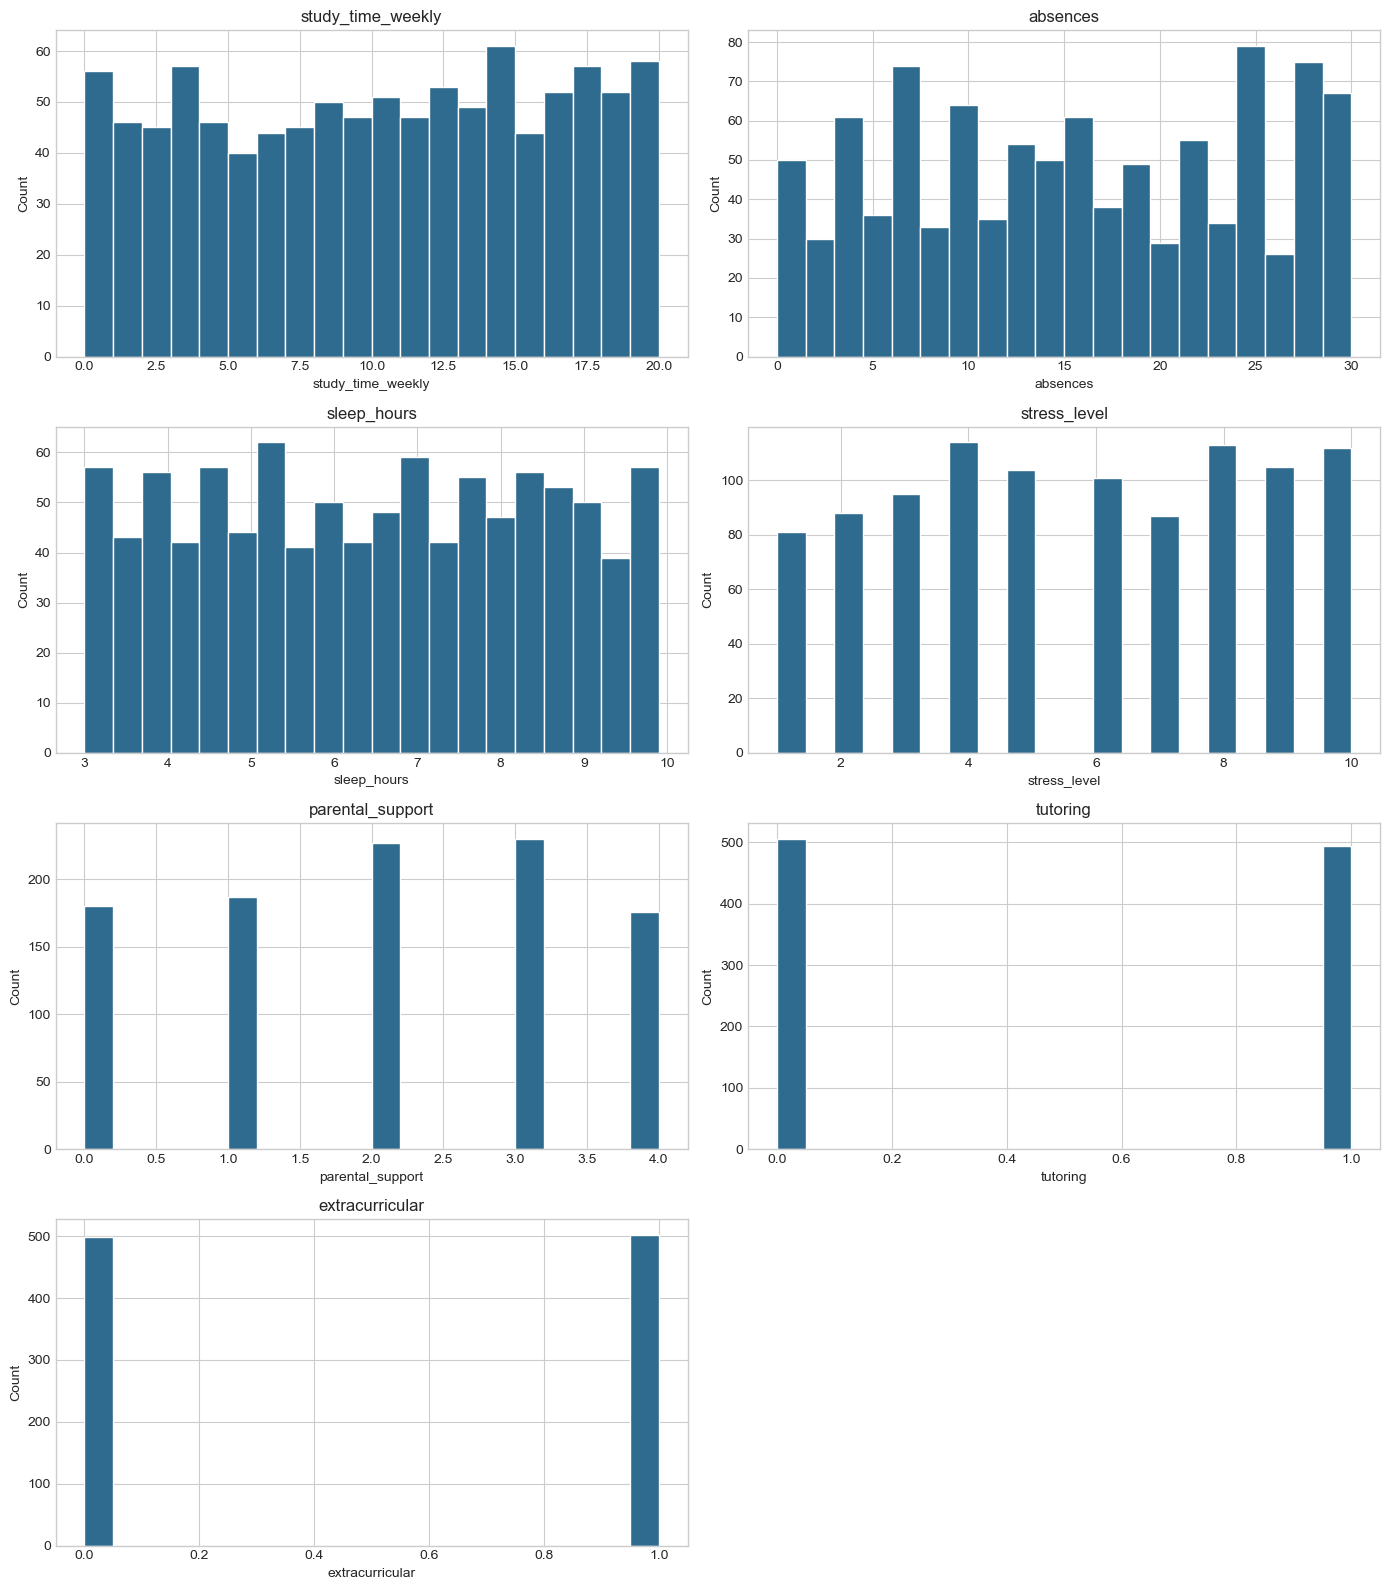

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for idx, col in enumerate(numeric_cols):
    axes[idx].hist(df[col], bins=20, color='#2f6b8f', edgecolor='white')
    axes[idx].set_title(col)
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Count')

fig.delaxes(axes[-1])
fig.tight_layout()
plt.show()

## 4. Relationship with the target

We compare the main features against the target to see which variables separate the classes better.

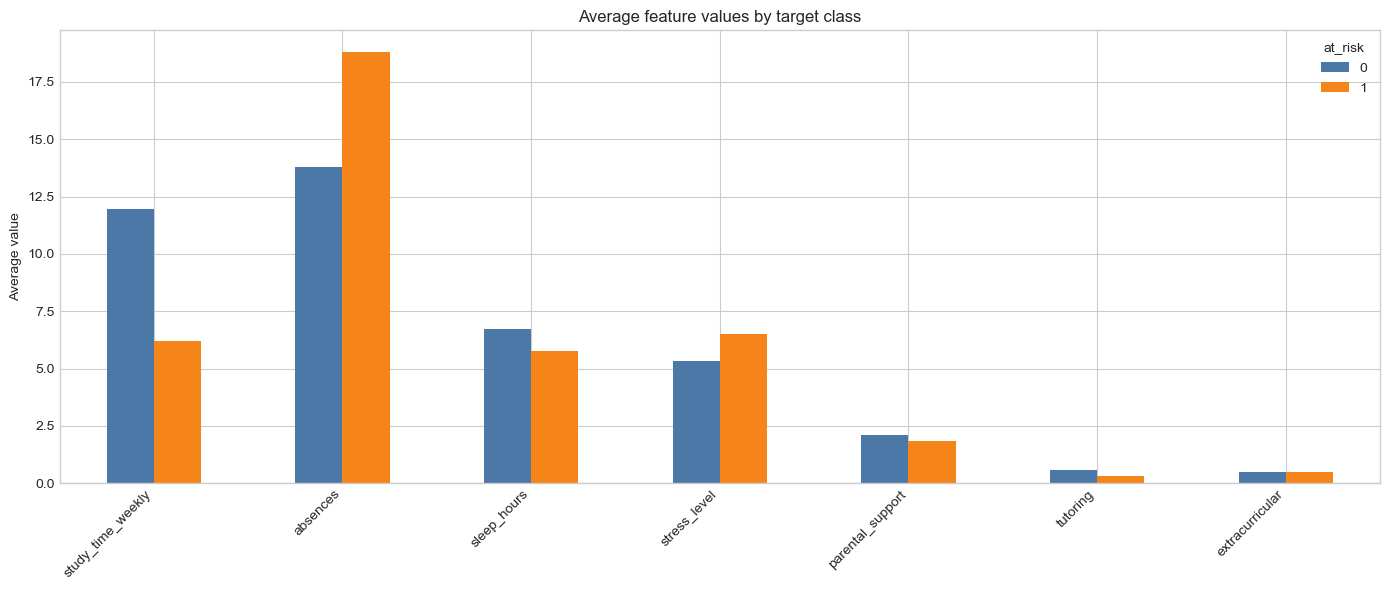

In [8]:
target_means = df.groupby('at_risk')[numeric_cols].mean().T

a = target_means.plot(kind='bar', figsize=(14, 6), color=['#4c78a8', '#f58518'])
a.set_ylabel('Average value')
a.set_title('Average feature values by target class')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Correlation analysis and final insights

A correlation matrix helps us understand which variables move together and which are most linked to the target.

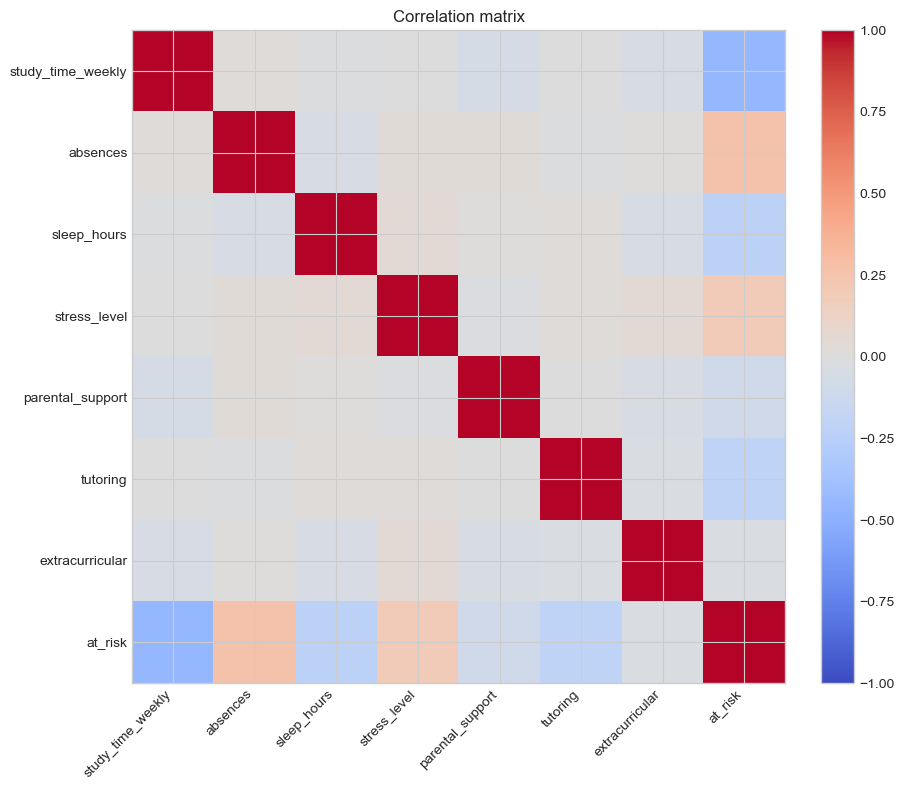

Top correlations with at_risk:
study_time_weekly   -0.45
absences             0.26
sleep_hours         -0.22
tutoring            -0.21
stress_level         0.19
parental_support    -0.09
extracurricular     -0.03
Name: at_risk, dtype: float64

Final insights:
- Lower study time and more absences are associated with higher academic risk.
- Sleep and support variables help reduce risk, but not as strongly as study time and absences.
- The target is imbalanced, so class metrics will matter when training models.


In [9]:
correlation_cols = numeric_cols + ['at_risk']
corr = df[correlation_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.index)
ax.set_title('Correlation matrix')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print('Top correlations with at_risk:')
print(corr['at_risk'].drop('at_risk').sort_values(key=lambda s: s.abs(), ascending=False))

print('\nFinal insights:')
print('- Lower study time and more absences are associated with higher academic risk.')
print('- Sleep and support variables help reduce risk, but not as strongly as study time and absences.')
print('- The target is imbalanced, so class metrics will matter when training models.')